# AgriOptima: mandi maize price prediction

Predict next month’s **national monthly median maize modal price**, in rupees per quintal. This is not a live quote for a particular mandi. We added downloaded 2024–2026 records and kept the original, easy-to-explain Linear Regression algorithm.

Read each section and run cells in order. No custom functions or classes are defined. The original application artifact is not overwritten.

## Libraries and output folder

In [1]:
"""Extended maize data: monthly Linear Regression with honest baseline comparisons."""
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()
if not (ROOT / 'DataSets').exists():
    ROOT = ROOT.parent
assert (ROOT / 'DataSets').exists(), 'Open Jupyter in the project folder.'
output = ROOT / 'results/mandi_prices'
output.mkdir(parents=True, exist_ok=True)


## 1. Read and clean the data
The extension adds 159,336 downloaded maize records. Invalid prices/dates are removed. Old data stops in 2023, and the extension supplies 2024 onward, so overlapping records are not counted twice. The combined table contains 1,226,081 valid reported records.

The new file is a third-party compilation attributed to AGMARKNET, not a direct download independently verified with the government. Source revision and CSV checksums are recorded in DataSets/mandi_maize_extension/source_manifest.json.

In [2]:
# 1. Read the original maize file and the newly downloaded records.
old = pd.read_csv(ROOT / 'DataSets/india_mandi_prices_2000_2024/Maize.csv', low_memory=False)
old = old.drop_duplicates().rename(columns={
    'Reported Date': 'date', 'Modal Price (Rs./Quintal)': 'price'})
old['date'] = pd.to_datetime(old['date'], format='%d %b %Y', errors='coerce')
parts = []
for path in sorted((ROOT / 'DataSets/mandi_maize_extension').glob('maize_*.csv')):
    frame = pd.read_csv(path).drop_duplicates().rename(columns={
        'Arrival_Date': 'date', 'Modal_Price': 'price'})
    frame['date'] = pd.to_datetime(frame['date'], errors='coerce')
    parts.append(frame)
assert len(parts) == 3, 'Download the 2024, 2025 and 2026 maize extracts first.'
new = pd.concat(parts, ignore_index=True)
# New source replaces ALL of 2024 onward. Do not count the overlap twice.
raw = pd.concat([old[old['date'] < '2024-01-01'],
                 new[new['date'] >= '2024-01-01']], ignore_index=True)
raw['price'] = pd.to_numeric(raw['price'], errors='coerce')
valid = raw['date'].notna() & np.isfinite(raw['price']) & raw['price'].gt(0)
valid = valid & raw['date'].le('2026-11-14')
clean = raw.loc[valid, ['date', 'price']].copy()
print('Downloaded extension records:', len(new))
print('Combined clean records:', len(clean))
print('Rejected records:', (~valid).sum())


Downloaded extension records: 159336
Combined clean records: 1226081
Rejected records: 4201


## 2. Make monthly inputs and check coverage
A month’s target is the median of its reported prices. Lag 1 is the actual previous calendar month; lag 12 is the same month a year earlier. Missing calendar months are left missing. Having many daily records does not mean millions of monthly training examples: there are only 291 model-ready months through April 2026.

Training starts before January 2023. Validation covers 2023–2024. Testing covers 2025. No 2026 prices are used in fitting or scoring this experiment. At least 20 reporting days in the target month and lag months is a coverage screen, not proof that every mandi reported.

In [3]:
# 2. One monthly target: median of reported maize modal prices across India.
# Count reporting days so a small fragment of a month is not called complete.
clean['month_date'] = clean['date'].dt.to_period('M').dt.to_timestamp()
monthly = clean.groupby('month_date').agg(
    price=('price', 'median'), reports=('price', 'size'),
    reporting_days=('date', 'nunique'), last_report=('date', 'max'))
monthly = monthly.asfreq('MS')
monthly.index.name = 'date'
for lag in [1, 2, 3, 12]:
    monthly[f'lag_{lag}'] = monthly['price'].shift(lag)
monthly['month'] = monthly.index.month
monthly['year'] = monthly.index.year
features = ['lag_1', 'lag_2', 'lag_3', 'lag_12', 'month', 'year']
# At least 20 reporting days is a screening rule, not proof of full coverage.
monthly['coverage_eligible'] = monthly['reporting_days'].ge(20)
for lag in [1, 2, 3, 6, 12]:
    monthly['coverage_eligible'] &= monthly['reporting_days'].shift(lag).ge(20)
data = monthly.dropna(subset=['price'] + features).reset_index()
data.to_csv(output / 'monthly_data.csv', index=False)
# All 2026 records are retained for review, but excluded from this evaluation.
validation = data[(data['date'] >= '2023-01-01') & (data['date'] < '2025-01-01')]
test = data[(data['date'] >= '2025-01-01') & (data['date'] < '2026-01-01')]
assert len(validation) == 24 and len(test) == 12


### What the expanded data shows

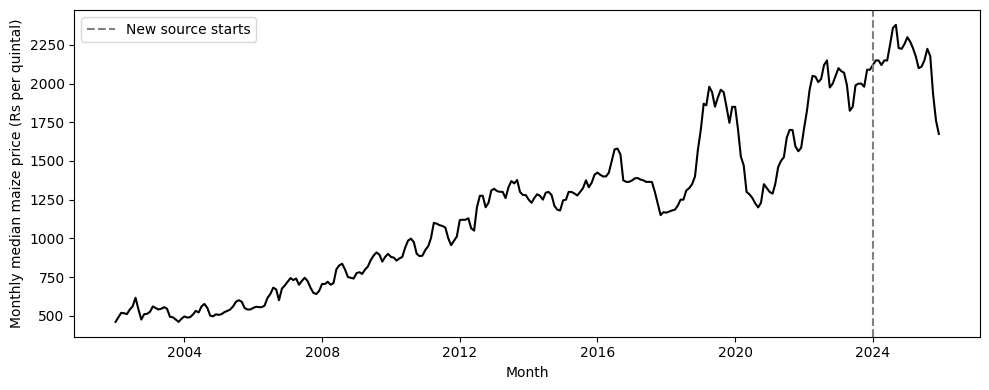

In [4]:
shown = data[data['date'] < '2026-01-01']
plt.figure(figsize=(10, 4))
plt.plot(shown['date'], shown['price'], color='black')
plt.axvline(pd.Timestamp('2024-01-01'), color='gray', linestyle='--', label='New source starts')
plt.ylabel('Monthly median maize price (Rs per quintal)')
plt.xlabel('Month')
plt.legend()
plt.tight_layout()
plt.show()


The line describes reported prices over time. The dashed line marks a change of source. In January 2024, the old and new source medians differ by Rs 9 (2111 versus 2120), so the sources are close in that overlap month but not identical.

## 3. Build Linear Regression
The equation combines earlier prices, year and a seasonal adjustment. We keep the existing algorithm and inputs. One-hot encoding lets each month have a different adjustment. More complicated models were also compared in a separate audit, but did not beat persistence on validation.

In [5]:
# 3. Keep the existing Linear Regression algorithm and its original inputs.
# Month is a season category; January=1 is not a linear price multiplier.
model_template = make_pipeline(
    ColumnTransformer([
        ('month', OneHotEncoder(categories=[list(range(1, 13))], drop='first',
                               handle_unknown='ignore'), ['month']),
        ('numbers', 'passthrough', ['lag_1', 'lag_2', 'lag_3', 'lag_12', 'year']),
    ]), LinearRegression())


## 4. Predict later months using earlier months
For January 2025, train only through December 2024. Once January is observed, include it before predicting February. This monthly update is a realistic one-month-ahead procedure. No future target is included in the current fit. All earlier reporting rows are retained in training; coverage flags are also reported so sparse history is visible.

In [6]:
# 4. Predict one month at a time, always training only on EARLIER months.
# Refit after a month is observed. Never shuffle a time series into train/test.
rows = []
for split, future in [('validation', validation), ('test', test)]:
    for index in future.index:
        past = data.iloc[:index]
        assert past['date'].max() < data.loc[index, 'date']
        model = clone(model_template)
        model.fit(past[features], past['price'])
        prediction = model.predict(data.loc[[index], features])[0]
        rows.append({
            'split': split, 'date': data.loc[index, 'date'],
            'actual': data.loc[index, 'price'], 'linear_prediction': prediction,
            'baseline_prediction': data.loc[index, 'lag_1'],
            'coverage_eligible': bool(data.loc[index, 'coverage_eligible']),
            'training_last_month': past['date'].max(),
        })
results = pd.DataFrame(rows)
results.to_csv(output / 'predictions.csv', index=False)


## 5. Compare with the simple baseline
The baseline repeats last month’s price. MAE means the average absolute error; a smaller number is better. Show validation and test results, and keep the complete-year result alongside the coverage-screened result. Do not select a model simply because it wins the test.

In [7]:
# 5. Show BOTH periods and BOTH coverage views. Do not hide the losing period.
metric_rows = []
for split in ['validation', 'test']:
    for view in ['all_months', 'coverage_screened']:
        subset = results[results['split'] == split]
        if view == 'coverage_screened':
            subset = subset[subset['coverage_eligible']]
        for label, column in [('Linear Regression', 'linear_prediction'),
                              ('Previous-month baseline', 'baseline_prediction')]:
            metric_rows.append({
                'split': split, 'coverage': view, 'method': label,
                'months': len(subset),
                'mae': mean_absolute_error(subset['actual'], subset[column]),
                'rmse': mean_squared_error(subset['actual'], subset[column]) ** 0.5,
                'r2': r2_score(subset['actual'], subset[column]),
            })
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(output / 'metrics.csv', index=False)
print(metrics.to_string(index=False))

     split          coverage                  method  months       mae      rmse       r2
validation        all_months       Linear Regression      24 54.278574 63.576534 0.775698
validation        all_months Previous-month baseline      24 48.541667 70.373705 0.725173
validation coverage_screened       Linear Regression      24 54.278574 63.576534 0.775698
validation coverage_screened Previous-month baseline      24 48.541667 70.373705 0.725173
      test        all_months       Linear Regression      12 47.606560 62.775829 0.892329
      test        all_months Previous-month baseline      12 76.666667 99.977497 0.726902
      test coverage_screened       Linear Regression      10 41.017159 57.418346 0.668677
      test coverage_screened Previous-month baseline      10 66.400000 91.460374 0.159347


**Interpretation:** On all 12 months of 2025, the updated linear model has MAE Rs 47.61 per quintal, versus Rs 76.67 for persistence: about 37.9% lower error. On the 10 months passing the coverage screen, it is Rs 41.02 versus Rs 66.40.

**The earlier validation period tells a different story:** linear MAE is Rs 54.28 versus Rs 48.54 for persistence. That period favours the baseline. Therefore we can say the updated linear model performed better on the 2025 test, but cannot say it is the best model in every period. The frozen candidate-selection audit actually selects persistence based on validation. The linear model is retained as the pre-existing research model, not presented as the validation winner.

## 2. Make monthly inputs and check coverage
A month’s target is the median of its reported prices. Lag 1 is the actual previous calendar month; lag 12 is the same month a year earlier. Missing calendar months are left missing. Having many daily records does not mean millions of monthly training examples: there are only 291 model-ready months through April 2026.

Training starts before January 2023. Validation covers 2023–2024. Testing covers 2025. No 2026 prices are used in fitting or scoring this experiment. At least 20 reporting days in the target month and lag months is a coverage screen, not proof that every mandi reported.

In [8]:
# 2025 improvement does not prove the model will beat persistence every year.
# Validation still favours persistence. Keep this model a research forecast.


## 6. See where the predictions are close
The black line is the recorded target. A predicted line nearer to it has less error for that month. November’s record covers only five days; December uses that sparse November value as an input. The shaded period remains visible in the full-year comparison.

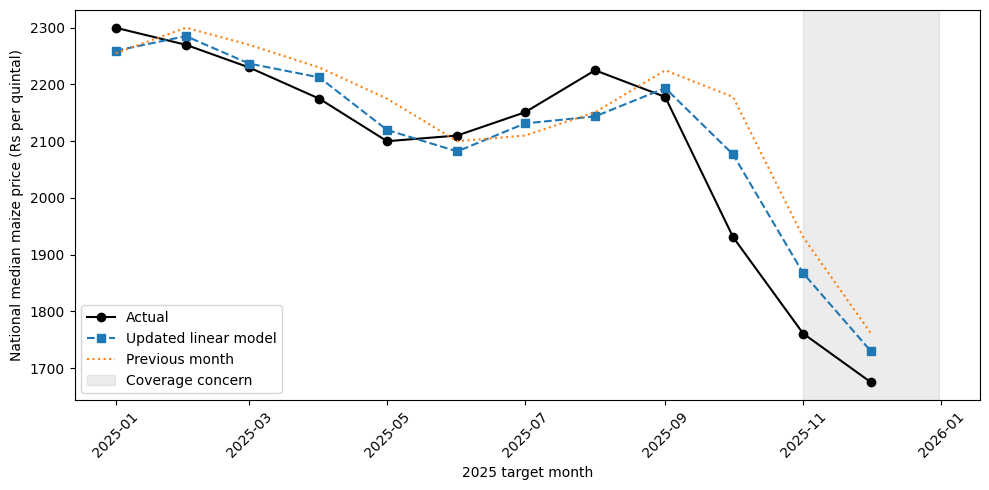

In [9]:
# 6. Draw actual versus predicted prices. Unscreened months remain visible.
test_results = results[results['split'] == 'test']
plt.figure(figsize=(10, 5))
plt.plot(test_results['date'], test_results['actual'], 'o-', color='black', label='Actual')
plt.plot(test_results['date'], test_results['linear_prediction'], 's--', label='Updated linear model')
plt.plot(test_results['date'], test_results['baseline_prediction'], ':', label='Previous month')
plt.axvspan(pd.Timestamp('2025-11-01'), pd.Timestamp('2025-12-31'),
            color='gray', alpha=0.15, label='Coverage concern')
plt.ylabel('National median maize price (Rs per quintal)')
plt.xlabel('2025 target month')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(output / 'predictions_2025.png', dpi=150)
plt.show()


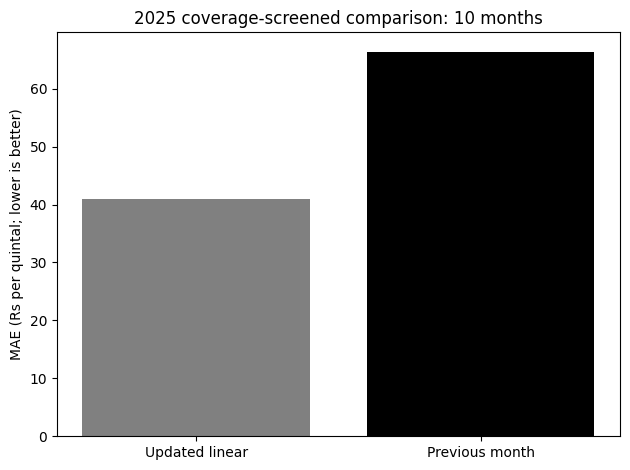

In [10]:
screened = metrics[(metrics['split'] == 'test') & (metrics['coverage'] == 'coverage_screened')]
plt.bar(['Updated linear', 'Previous month'], screened['mae'], color=['gray', 'black'])
plt.ylabel('MAE (Rs per quintal; lower is better)')
plt.title('2025 coverage-screened comparison: 10 months')
plt.tight_layout()
plt.savefig(output / 'error_comparison.png', dpi=150)
plt.show()


Each bar is the average absolute prediction error across the same ten months. This figure does not compare the old 2023–2024 test with the newer 2025 test: the time periods and prices differ.

## 7. Save a separate research model
This final fit uses the available history through October 2025, before the coverage gap. Its scores above were calculated using separate earlier-only fits, not this final artifact. The saved model needs exact past-month price inputs for a one-month-ahead estimate. It is a historical research model, not a current price service.

In [11]:
# 7. Save separately. Fit only pre-November-2025 history for the next estimate.
# This refit is NOT used to compute the test scores above.
training = data[data['date'] < '2025-11-01']
final_model = clone(model_template).fit(training[features], training['price'])
artifact_dir = ROOT / 'saved_models'
artifact_dir.mkdir(parents=True, exist_ok=True)
joblib.dump({
    'model': final_model, 'features': features,
    'training_last_month': str(training['date'].max().date()),
    'target': 'National monthly median maize modal price, Rs/quintal',
    'forecast_horizon': 'one month ahead; actual calendar lags required',
    'status': 'research model; validation does not beat persistence',
}, artifact_dir / 'maize_price_extended_linear.joblib')
# This is a historical research model, not a live November-2026 price service.
print('Saved extended linear model separately; original artifacts are unchanged.')

Saved extended linear model separately; original artifacts are unchanged.


## What to explain in the viva
“We added later reported maize prices, checked duplicates and incomplete coverage, and retrained our existing linear model each month. It performed better than repeating last month’s price on the 2025 test, but not on validation. We report both periods and keep incomplete-month warnings visible.”

**Limits:** a single test year; source-composition changes in 2024; varying mandi coverage; no arrivals information in the extension; national aggregate rather than farmer-specific prices. The coverage screen is a sensitivity analysis documented alongside the originally planned full-year test. The 2025 results have now been inspected, so later changes must not call 2025 a fresh untouched test.

**Where to find the work:** results/mandi_prices contains tables and plots; saved_models/maize_price_extended_linear.joblib is the separate research model. Earlier candidate comparisons are preserved in the recovery copy outside this project.